# 01 · Closure & Error Calibration

**Question this notebook answers:** when the interpreter fits the *correct*
model to noisy data, does it (a) recover the input parameters without bias and
(b) report error bars you can trust?

This is the single most important test for the "are the results robust?"
concern. We use `CosineCosmology` as both the truth and the interpreter model
with **no systematics**, so a healthy pipeline must return χ²/dof ≈ 1,
recover the input frequency, and produce *pulls* — (best-fit − truth)/σ —
that follow a standard normal distribution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import mstest_utils as mu          # shared helpers (lives in metascience/python/)
import interpret, cosmology, consensus

np.random.seed(0)
plt.rcParams['figure.figsize'] = (8, 4.5)

## 1. Single closure fit
Fit the true model to one noise realization and look at the fit and residuals.

Initial guess:[0.5 2.  0.  0. ]
best fit:[0.49922845 1.9986991  0.00209384 0.00816035]


truth   [w, amp, phase]: [0.5 2.  0. ]
best-fit cosmological  : [0.49922845]
best-fit nuisance      : [1.9986991  0.00209384]
1-sigma error on w     : 0.0006139798214399038
chi2/dof               : 0.999


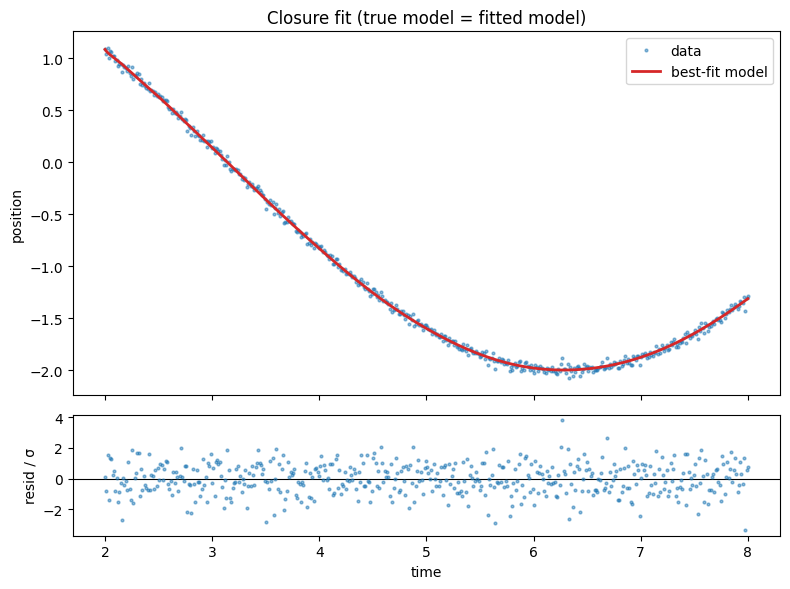

In [2]:
exp, interp, truth = mu.run_fit(truth_name='CosineCosmology',
                                interp_name='CosineCosmology',
                                noise=0.03, times='times_A.txt', seed=110)

print('truth   [w, amp, phase]:', truth)
print('best-fit cosmological  :', interp.best_fit_cosmological_parameters)
print('best-fit nuisance      :', interp.best_fit_nuisance_parameters)
print('1-sigma error on w     :', mu.cosmo_errors(interp)[0])
print('chi2/dof               :', round(mu.chi2_per_dof(interp), 3))

fig, (a0, a1) = plt.subplots(2, 1, sharex=True, figsize=(8, 6),
                             gridspec_kw={'height_ratios':[3,1]})
a0.plot(exp.times, exp.observed_data_vector, '.', ms=4, alpha=.5, label='data')
a0.plot(interp.times, interp.best_fit_observed_model, 'C3', lw=2, label='best-fit model')
a0.set_ylabel('position'); a0.legend(); a0.set_title('Closure fit (true model = fitted model)')
resid = exp.observed_data_vector - interp.best_fit_observed_model
a1.axhline(0, color='k', lw=.8)
a1.plot(interp.times, resid/0.03, '.', ms=4, alpha=.5)
a1.set_ylabel('resid / σ'); a1.set_xlabel('time')
plt.tight_layout()

## 2. Error calibration over many realizations

Repeat the fit over many independent noise realizations and histogram the
pulls. For calibrated errors the pulls should have **mean ≈ 0**, **std ≈ 1**,
and the 1σ interval should contain the truth ~68% of the time.

Initial guess:[0.5 2.  0.  0. ]
best fit:[ 5.00568168e-01  2.00051898e+00 -6.53724461e-04 -8.29764355e-03]


Initial guess:[0.5 2.  0.  0. ]
best fit:[ 0.49908406  2.00035577  0.0032125  -0.00783182]


Initial guess:[0.5 2.  0.  0. ]
best fit:[0.49886949 2.00008164 0.00558055 0.01578591]


Initial guess:[0.5 2.  0.  0. ]
best fit:[0.49921926 1.99744443 0.00373515 0.00922061]


Initial guess:[0.5 2.  0.  0. ]
best fit:[4.99874832e-01 1.99930646e+00 5.71172570e-05 9.13383395e-03]


Initial guess:[0.5 2.  0.  0. ]
best fit:[ 0.50083541  1.99993662 -0.00225476 -0.00263857]


... (111 outputs left out)

Initial guess:[0.5 2.  0.  0. ]
best fit:[ 0.50102169  1.9998337  -0.00386086  0.0038341 ]


Initial guess:[0.5 2.  0.  0. ]
best fit:[0.49937685 1.99694743 0.00201487 0.00363141]


Initial guess:[0.5 2.  0.  0. ]
best fit:[ 5.00505680e-01  1.99916610e+00 -1.60583096e-03  1.81828119e-03]


realizations : 120
pull mean    : +0.083   (ideal 0)
pull std     : 0.947    (ideal 1)
68% coverage : 71%   (ideal 68%)
95% coverage : 97%   (ideal 95%)


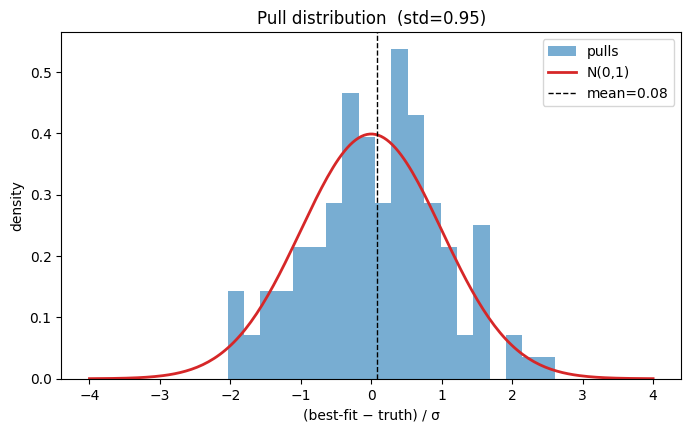

In [3]:
N = 120   # increase for smoother statistics (runtime scales linearly)
pulls = mu.coverage_experiment(n_realizations=N, which=0, base_seed=1000,
                               truth_name='CosineCosmology',
                               interp_name='CosineCosmology', noise=0.03)

print(f'realizations : {N}')
print(f'pull mean    : {pulls.mean():+.3f}   (ideal 0)')
print(f'pull std     : {pulls.std():.3f}    (ideal 1)')
print(f'68% coverage : {np.mean(np.abs(pulls)<1)*100:.0f}%   (ideal 68%)')
print(f'95% coverage : {np.mean(np.abs(pulls)<2)*100:.0f}%   (ideal 95%)')

xs = np.linspace(-4, 4, 200)
plt.hist(pulls, bins=20, density=True, alpha=.6, label='pulls')
plt.plot(xs, np.exp(-xs**2/2)/np.sqrt(2*np.pi), 'C3', lw=2, label='N(0,1)')
plt.axvline(pulls.mean(), color='k', ls='--', lw=1, label=f'mean={pulls.mean():.2f}')
plt.xlabel('(best-fit − truth) / σ'); plt.ylabel('density')
plt.title(f'Pull distribution  (std={pulls.std():.2f})'); plt.legend();

### How to read this
- **mean ≈ 0** → the fit is unbiased.
- **std ≈ 1 and 68% coverage ≈ 68%** → the reported σ is trustworthy.
- **std > 1 / coverage < 68%** → σ is too small (over-confident); **std < 1** → too large.

At modest `N` the pull std wanders around 1 by a few ×1/√(2N); don't over-read a
single run. For this nonlinear (cosine) model the formal Fisher error is close to
calibrated but not exact, so if a run lands consistently off 1 after raising `N`,
prefer the profile-likelihood error (notebook 02) or apply a calibration factor.
Increase `N` before drawing any conclusion.
